<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X3b_duais_sistemas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio III (b): sistemas de equações com números duais

## Sensibilidade de graça, jacobianos automáticos, e o equilíbrio de uma barra que gira e desliza

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 3](X3_duais.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X3_duais.ipynb)) · **Anterior:** [X3a_duais_algebra.ipynb](X3a_duais_algebra.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X3a_duais_algebra.ipynb)) · **Próximo:** [X3c_duais_edo.ipynb](X3c_duais_edo.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X3c_duais_edo.ipynb))

**Objetivo.** Usar os números duais do notebook III(a) nos três tipos de sistema da série:
- **sistemas lineares com coeficientes duais:** a parte dual da solução é a **sensibilidade** da solução a um parâmetro. Quanto cada bloco do notebook I(b) se move se uma mola endurecer um pouco? Um sistema dual responde, exatamente;
- **sistemas não lineares:** o jacobiano do Newton sai por **derivação automática**, coluna por coluna, sem deduzir nada à mão;
- **mínimos quadrados:** o jacobiano dos resíduos em relação aos parâmetros, mesmo quando cada resíduo exige resolver um sistema não linear, sai passando os números duais **através do próprio solucionador**.

**O fio físico.** Uma barra presa a um eixo vertical por uma **junta cilíndrica**: ela gira (ângulo $\theta$) e desliza (altura $d$). Uma mola de torção resiste ao giro, uma mola axial resiste ao deslizamento, a gravidade puxa para baixo, e um **fio** preso à ponta da barra puxa na direção de um ponto fixo. Onde a barra para?

**Roteiro**
1. Sistemas lineares com coeficientes duais: sensibilidade
2. Jacobianos por números duais
3. O equilíbrio da barra: Newton, vários equilíbrios e estabilidade
4. Identificar as molas: Gauss–Newton através do solucionador
5. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido, dtype=float), np.asarray(esperado, dtype=float)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import sympy as sp
from scipy import optimize
import time
rng = np.random.default_rng(32)

class Dual:
    """Número dual re + ε·du (notebook III(a)); re e du podem ser floats ou arrays."""
    __array_priority__ = 1000
    def __init__(self, re, du=0.0): self.re, self.du = re, du
    @staticmethod
    def _d(o): return o if isinstance(o, Dual) else Dual(o, 0.0)
    def __add__(self, o): o = Dual._d(o); return Dual(self.re + o.re, self.du + o.du)
    __radd__ = __add__
    def __neg__(self): return Dual(-self.re, -self.du)
    def __sub__(self, o): return self + (-Dual._d(o))
    def __rsub__(self, o): return Dual._d(o) - self
    def __mul__(self, o): o = Dual._d(o); return Dual(self.re * o.re, self.re * o.du + self.du * o.re)
    __rmul__ = __mul__
    def __truediv__(self, o): o = Dual._d(o); return Dual(self.re / o.re, (self.du * o.re - self.re * o.du) / o.re**2)
    def __rtruediv__(self, o): return Dual._d(o) / self
    def __pow__(self, n): return Dual(self.re**n, n * self.re**(n - 1) * self.du)
    def __repr__(self): return f"{self.re} + ε·{self.du}"

def _eleva(f, df):
    return lambda x: Dual(f(x.re), df(x.re) * x.du) if isinstance(x, Dual) else f(x)
sin, cos = _eleva(np.sin, np.cos), _eleva(np.cos, lambda a: -np.sin(a))
sqrt = _eleva(np.sqrt, lambda a: 0.5 / np.sqrt(a))
re = lambda v: np.array([x.re if isinstance(x, Dual) else x for x in v], float)
du = lambda v: np.array([x.du if isinstance(x, Dual) else 0.0 for x in v], float)

---

## 1. Sistemas lineares com coeficientes duais: sensibilidade

Os três blocos entre paredes do notebook I(b) obedecem a $\mathbf K\mathbf x=\mathbf f$. Suponha que a mola 2 tenha constante $k_2+\varepsilon$: a matriz passa a ser dual, $\mathbf K_0+\varepsilon\mathbf K_1$, com $\mathbf K_1=\partial\mathbf K/\partial k_2$. Procurando a solução também dual, $\mathbf x_0+\varepsilon\mathbf x_1$, e separando as partes:

$$(\mathbf K_0+\varepsilon\mathbf K_1)(\mathbf x_0+\varepsilon\mathbf x_1)=\mathbf f\quad\Longrightarrow\quad\mathbf K_0\mathbf x_0=\mathbf f,\qquad \mathbf K_0\mathbf x_1=-\mathbf K_1\mathbf x_0 .$$

A parte dual $\mathbf x_1$ é exatamente $\partial\mathbf x/\partial k_2$: quanto cada bloco se desloca por unidade de aumento da rigidez da mola 2. E o custo é pequeno: **a mesma matriz** $\mathbf K_0$ resolve os dois sistemas (uma fatoração LU só, reaproveitada). A célula compara com a derivada exata do `sympy` e com diferenças finitas.

In [2]:
def rigidez(ks):
    n = len(ks) - 1
    K = np.zeros((n, n), dtype=object if isinstance(ks[0], (Dual, sp.Basic)) else float)
    for i in range(n):
        K[i, i] = ks[i] + ks[i + 1]
        if i + 1 < n:
            K[i, i + 1] = K[i + 1, i] = -ks[i + 1]
    return K

def resolve_dual(A0, A1, b0, b1):
    """(A0 + εA1)(x0 + εx1) = b0 + εb1, com uma fatoração só de A0."""
    from scipy.linalg import lu_factor, lu_solve
    lu = lu_factor(A0)
    x0 = lu_solve(lu, b0)
    return x0, lu_solve(lu, b1 - A1 @ x0)

ks = [100.0, 50.0, 80.0, 120.0]; f = np.array([2.0, -1.0, 3.0])
K0 = rigidez(ks)
K1 = rigidez([0.0, 1.0, 0.0, 0.0])                      # ∂K/∂k2: só a mola 2 muda
x0, x1 = resolve_dual(K0, K1, f, np.zeros(3))
print("deslocamentos (m):        ", x0)
print("∂x/∂k2 (m por N/m), dual: ", x1)

k2 = sp.Symbol("k2", positive=True)
Ks = sp.Matrix(rigidez([sp.Integer(100), k2, sp.Integer(80), sp.Integer(120)]))
xs = Ks.LUsolve(sp.Matrix([2, -1, 3]))
dxs = [float(sp.diff(e, k2).subs(k2, 50)) for e in xs]
confere("parte dual = derivada exata do sympy", x1, dxs, tol=1e-17)
h = 1e-4
x_mais = np.linalg.solve(rigidez([100.0, 50.0 + h, 80.0, 120.0]), f); x_menos = np.linalg.solve(rigidez([100.0, 50.0 - h, 80.0, 120.0]), f)
print(f"diferença central (h = 1e-4): erro {np.max(np.abs((x_mais - x_menos) / (2 * h) - dxs)):.1e};  dual: erro {np.max(np.abs(x1 - dxs)):.1e}")
print("fórmula de sensibilidade −K⁻¹(∂K/∂k2)x:", -np.linalg.solve(K0, K1 @ x0))

deslocamentos (m):         [0.016885 0.010656 0.019262]
∂x/∂k2 (m por N/m), dual:  [-0.000025  0.000051  0.00002 ]
OK   parte dual = derivada exata do sympy:  diferença máxima = 1.36e-20
diferença central (h = 1e-4): erro 3.2e-14;  dual: erro 1.4e-20
fórmula de sensibilidade −K⁻¹(∂K/∂k2)x: [-0.000025  0.000051  0.00002 ]


**Leitura.** Endurecer a mola 2 (a que liga os blocos 1 e 2) aproxima os deslocamentos desses dois blocos um do outro; o sinal de cada componente de $\partial\mathbf x/\partial k_2$ diz para que lado cada bloco vai. O resultado dual coincide com a derivada simbólica até o arredondamento, e é a fórmula clássica de sensibilidade, $-\mathbf K^{-1}(\partial\mathbf K/\partial k)\mathbf x$, que os engenheiros deduzem à mão, aqui obtida sem dedução nenhuma.

> **Nota: o elo com o Kalman.** A covariância $\mathbf P$ de um filtro de Kalman responde à mesma pergunta em forma estatística: quanto o estado estimado muda se as medidas mudarem. Sensibilidades e covariâncias andam juntas: $\mathbf P\approx\sigma^2(\mathbf J^\top\mathbf J)^{-1}$, e $\mathbf J$ é uma matriz de sensibilidades.

---

## 2. Jacobianos por números duais

Para uma função $\mathbf g:\mathbb R^n\to\mathbb R^m$, a coluna $j$ do jacobiano é a derivada de $\mathbf g$ na direção do eixo $j$. Com números duais, basta avaliar $\mathbf g$ uma vez com a entrada $j$ "semeada": $x_j+\varepsilon$, e as outras sem parte dual. São $n$ avaliações para o jacobiano inteiro, cada uma exata.

In [3]:
def jacobiano_dual(g, x, *args):
    """Jacobiano de g em x por derivação automática (modo direto): uma passada por coluna."""
    x = np.asarray(x, float)
    colunas = []
    for j in range(len(x)):
        xd = [Dual(x[i], 1.0 if i == j else 0.0) for i in range(len(x))]
        colunas.append(du(g(*xd, *args)))
    return np.column_stack(colunas)

def jacobiano_dif(g, x, *args, h=1e-6):
    x = np.asarray(x, float)
    return np.column_stack([(re(g(*(x + e), *args)) - re(g(*(x - e), *args))) / (2 * h) for e in np.eye(len(x)) * h])

# um teste: as forças nos dois blocos com molas de Duffing (notebook I(b), seção 4)
def g_duffing(x1, x2):
    F = lambda u: 100 * u + 5000 * u**3
    u1, u2, u3 = x1, x2 - x1, -x2
    return [F(u1) - F(u2) - 30, F(u2) - F(u3) + 20]

X1, X2 = sp.symbols("x1 x2")
J_sym = sp.Matrix(g_duffing(X1, X2)).jacobian([X1, X2])
J_exato = np.array(J_sym.subs({X1: 0.3, X2: -0.2}), dtype=float)
J_d, J_f = jacobiano_dual(g_duffing, [0.3, -0.2]), jacobiano_dif(g_duffing, [0.3, -0.2])
confere("jacobiano dual = jacobiano do sympy", J_d, J_exato, tol=1e-12)
print(f"erro relativo máximo: dual {np.max(np.abs(J_d - J_exato)) / np.max(np.abs(J_exato)):.1e};"
      f"  diferenças centrais {np.max(np.abs(J_f - J_exato)) / np.max(np.abs(J_exato)):.1e}")

OK   jacobiano dual = jacobiano do sympy:  diferença máxima = 0.00e+00
erro relativo máximo: dual 0.0e+00;  diferenças centrais 4.7e-11


---

## 3. O equilíbrio da barra

**A montagem.** Um eixo vertical (o eixo $z$). Presa a ele por uma junta cilíndrica, uma barra horizontal de comprimento $\ell=0{,}5$ m e massa $m=1$ kg, que gira (ângulo $\theta$, medido a partir do eixo $x$) e desliza (altura $d$). Na ponta da barra, um fio passa por uma roldana no ponto fixo $\mathbf P=(-1{,}0;\ 0{,}2;\ 0{,}3)$ m e sustenta um peso: a tensão no fio é constante, $T=5$ N. Além disso:
- uma **mola de torção** com constante $k_\theta=0{,}2$ N·m/rad, que faz torque $-k_\theta\theta$ (em $\theta=0$ ela está relaxada);
- uma **mola axial** com constante $k_d=200$ N/m, que faz força $-k_d d$;
- o **peso** da barra, $-mg$.

**As equações.** A ponta da barra está em $\mathbf q=(\ell\cos\theta,\ \ell\sin\theta,\ d)$. O fio puxa na direção $\mathbf u=(\mathbf P-\mathbf q)/\|\mathbf P-\mathbf q\|$. No equilíbrio, o **torque** em torno do eixo e a **força** ao longo do eixo são zero:

$$g_1(\theta,d)=-k_\theta\theta+T\ell\,(-\sin\theta\,u_x+\cos\theta\,u_y)=0,\qquad g_2(\theta,d)=-k_d d-mg+T u_z=0 .$$

O primeiro termo de $g_1$ é o torque da mola; o segundo, o do fio (o braço $\ell$ vezes a componente da força perpendicular à barra).

**O ângulo não se enrola aqui.** A mola de torção **conta as voltas**: com $\theta=2\pi$, a barra está na mesma posição que em $\theta=0$, mas a mola está torcida de uma volta inteira, e faz força. Neste problema, $\theta$ é um número real, e não um ponto do círculo. A topologia do estado depende da física: sem a mola, $\theta$ seria um ângulo do círculo (notebook III(a), seção 5).

A função abaixo funciona com números comuns e com duais, porque só usa operações que a classe `Dual` conhece.

In [4]:
L_B, M_B, G = 0.5, 1.0, 9.81
P_FIO = np.array([-1.0, 0.2, 0.3])

def forcas(th, d, k_th=0.2, k_d=200.0, T=5.0):
    """Torque em torno do eixo e força ao longo dele, na barra em (θ, d). Aceita duais em qualquer argumento."""
    vx, vy, vz = P_FIO[0] - L_B * cos(th), P_FIO[1] - L_B * sin(th), P_FIO[2] - d
    n = sqrt(vx * vx + vy * vy + vz * vz)
    ux, uy, uz = vx / n, vy / n, vz / n
    return [-k_th * th + T * L_B * (-sin(th) * ux + cos(th) * uy),
            -k_d * d - M_B * G + T * uz]

def newton_barra(x, *args, n_iter=100, tol=1e-13):
    """Newton amortecido: se o passo inteiro não diminui |g|, corta o passo ao meio (exercício 4 do notebook I(b))."""
    x = np.array(x, float)
    for _ in range(n_iter):
        g = re(forcas(*x, *args))
        dx = np.linalg.solve(jacobiano_dual(forcas, x, *args), -g)
        lam = 1.0
        while lam > 1e-4 and np.linalg.norm(re(forcas(*(x + lam * dx), *args))) > np.linalg.norm(g) and np.linalg.norm(dx) > tol:
            lam /= 2
        x = x + lam * dx
        if np.linalg.norm(dx) < tol:
            return x
    return None

# a energia potencial: as forças devem ser menos o gradiente dela
def energia(th, d, k_th=0.2, k_d=200.0, T=5.0):
    vx, vy, vz = P_FIO[0] - L_B * cos(th), P_FIO[1] - L_B * sin(th), P_FIO[2] - d
    return 0.5 * k_th * th * th + 0.5 * k_d * d * d + M_B * G * d + T * sqrt(vx * vx + vy * vy + vz * vz)

x_t = np.array([0.7, -0.03])
confere("forças = −∇(energia), com o gradiente por números duais",
        re(forcas(*x_t)), -jacobiano_dual(lambda a, b: [energia(a, b)], x_t)[0], tol=1e-12)

OK   forças = −∇(energia), com o gradiente por números duais:  diferença máxima = 0.00e+00


**Todos os equilíbrios.** O sistema é não linear e pode ter vários equilíbrios. A célula parte o Newton de 81 chutes de $\theta$ entre $-8$ e $8$ rad (mais de duas voltas para cada lado), guarda as soluções distintas e classifica cada uma: o equilíbrio é **estável** quando a energia potencial tem um **mínimo** ali, isto é, quando a matriz hessiana da energia, que é $-\mathbf J$ (o jacobiano das forças com o sinal trocado), é positiva definida.

  θ (rad)    θ (graus)   posição da barra (graus, enrolada)   d (mm)    estável?
  -9.0758      -520.0               -160.0                  -37.49    sim
  -7.4480      -426.7                -66.7                  -42.97    não
  -3.1814      -182.3                177.7                  -35.71    sim
  -0.2249       -12.9                -12.9                  -43.54    não
   2.8058       160.8                160.8                  -35.66    sim
   6.9853       400.2                 40.2                  -43.05    não
   8.7145       499.3                139.3                  -37.30    sim
OK     forças nulas em θ = -9.076:  diferença máxima = 8.88e-16
OK     forças nulas em θ = -7.448:  diferença máxima = 8.88e-16
OK     forças nulas em θ = -3.181:  diferença máxima = 8.88e-16
OK     forças nulas em θ = -0.225:  diferença máxima = 8.88e-16
OK     forças nulas em θ = 2.806:  diferença máxima = 5.55e-16
OK     forças nulas em θ = 6.985:  diferença máxima = 4.44e-16
OK     forças nulas

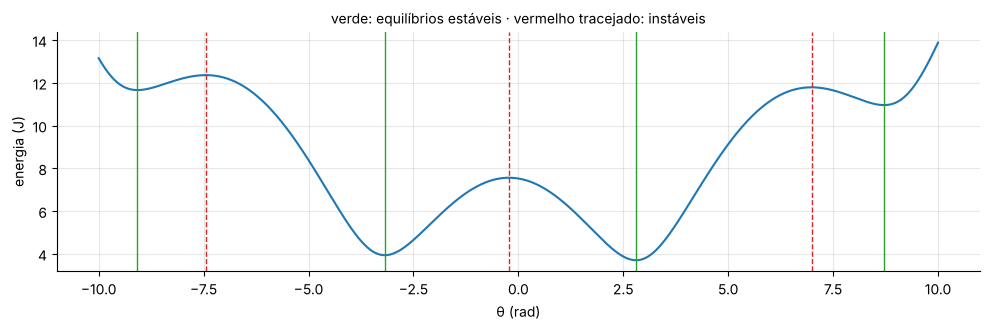

In [5]:
equilibrios = []
for th0 in np.linspace(-8, 8, 81):
    x = newton_barra([th0, 0.0])
    if x is not None and not any(abs(x[0] - e[0]) < 1e-6 for e in equilibrios):
        Hs = -jacobiano_dual(forcas, x)
        equilibrios.append((x[0], x[1], np.all(np.linalg.eigvalsh(0.5 * (Hs + Hs.T)) > 0)))
equilibrios.sort()
print("  θ (rad)    θ (graus)   posição da barra (graus, enrolada)   d (mm)    estável?")
for th_e, d_e, est in equilibrios:
    print(f"{th_e:9.4f}  {np.degrees(th_e):10.1f}   {np.degrees(np.arctan2(np.sin(th_e), np.cos(th_e))):18.1f}"
          f"                {1000 * d_e:8.2f}    {'sim' if est else 'não'}")
for th_e, d_e, _ in equilibrios:
    confere(f"  forças nulas em θ = {th_e:.3f}", re(forcas(th_e, d_e)), [0, 0], tol=1e-11)
ref = optimize.fsolve(lambda v: re(forcas(*v)), [2.5, 0.0], fprime=lambda v: jacobiano_dual(forcas, v), xtol=1e-13)
confere("scipy.optimize.fsolve concorda com um dos equilíbrios", min(abs(ref[0] - e[0]) for e in equilibrios), 0, tol=1e-9)

tt = np.linspace(-10, 10, 2000)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(tt, [energia(a, -0.04) for a in tt], label="energia potencial com d = −40 mm")
for th_e, d_e, est in equilibrios:
    ax.axvline(th_e, color="tab:green" if est else "tab:red", ls="-" if est else "--", lw=1)
ax.set_xlabel("θ (rad)"); ax.set_ylabel("energia (J)"); ax.set_title("verde: equilíbrios estáveis · vermelho tracejado: instáveis", fontsize=10)
plt.tight_layout(); plt.show()

**Leitura.** A mola de torção é fraca, e o fio consegue enrolar a barra várias vezes: há equilíbrios estáveis com a barra a mais de uma volta da posição relaxada, alternados com equilíbrios instáveis. Na coluna "posição da barra", vários equilíbrios estáveis apontam para quase a mesma direção física, mas com a mola torcida de um número diferente de voltas: são estados diferentes, e é por isso que, neste problema, o ângulo não se enrola. A altura $d$ muda pouco entre eles, menos de 1 cm (o peso domina a força axial).

Um Newton partindo de um chute qualquer acha **algum** equilíbrio, estável ou não. Para saber onde a barra realmente para, é preciso saber de onde ela partiu, e simular o movimento: é o assunto do notebook III(c).

---

## 4. Identificar as molas: Gauss–Newton através do solucionador

**O experimento.** Não conhecemos $k_\theta$ e $k_d$. Para medi-los, a roldana vai para $\mathbf P=(0{,}2;\ 1{,}0;\ 0{,}3)$ m, do lado de $+y$, de modo que o fio gira a barra num sentido só e o equilíbrio muda continuamente com a tensão, sem saltos entre equilíbrios. Variamos a tensão (pesos diferentes na roldana) de 0,05 a 0,4 N, partindo da barra relaxada e aumentando aos poucos, e medimos o ângulo e a altura de equilíbrio, com ruído de 0,5° e 0,5 mm. Queremos os $(k_\theta,k_d)$ que melhor explicam as medidas, por mínimos quadrados.

**A dificuldade.** O resíduo de cada medida é "equilíbrio previsto menos equilíbrio medido", e o equilíbrio previsto não tem fórmula: sai de um Newton. Para o Gauss–Newton (notebook I(b), seção 5), é preciso o jacobiano **do equilíbrio em relação aos parâmetros**.

**A solução com duais.** Basta rodar o Newton com o parâmetro dual, $k_\theta+\varepsilon$. Quando a parte real converge, a parte dual converge para $\partial\theta^*/\partial k_\theta$. Uma maneira simples de fazer isso: iterar $\mathbf x\leftarrow\mathbf x-\mathbf J_0^{-1}\mathbf g(\mathbf x,\mathbf k)$, com tudo dual exceto o jacobiano $\mathbf J_0$ (só a parte real). No ponto fixo, a parte dual satisfaz $\mathbf J_0\mathbf x_1+\partial\mathbf g/\partial k=\mathbf 0$, que é o **teorema da função implícita**:

$$\frac{\partial\mathbf x^*}{\partial k}=-\mathbf J_0^{-1}\frac{\partial\mathbf g}{\partial k}.$$

A célula confere as duas coisas: a derivação através do solucionador e a fórmula da função implícita.

In [6]:
def equilibrio(params, chute):
    """Equilíbrio para params = (k_θ, k_d, T), que podem ser duais. Devolve [θ*, d*] (duais se params forem)."""
    x0 = newton_barra(chute, *[p.re if isinstance(p, Dual) else p for p in params])
    J0 = jacobiano_dual(forcas, x0, *[p.re if isinstance(p, Dual) else p for p in params])
    x = [Dual(x0[0]), Dual(x0[1])]
    for _ in range(30):                                     # o mesmo Newton, agora carregando a parte dual
        g = forcas(*x, *params)
        passo_re = np.linalg.solve(J0, re(g)); passo_du = np.linalg.solve(J0, du(g))
        x = [Dual(x[i].re - passo_re[i], x[i].du - passo_du[i]) for i in range(2)]
    return x

xd = equilibrio((Dual(0.2, 1.0), 200.0, 5.0), [2.5, 0.0])
print(f"equilíbrio com k_θ = 0,2 + ε: θ* = {xd[0]},  d* = {xd[1]}")
x0 = re(xd)
dg_dk = du(forcas(Dual(x0[0]), Dual(x0[1]), Dual(0.2, 1.0)))     # ∂g/∂k_θ com x fixo
confere("através do solucionador = função implícita −J⁻¹ ∂g/∂k", du(xd), -np.linalg.solve(jacobiano_dual(forcas, x0), dg_dk), tol=1e-12)
h = 1e-6
dif = (newton_barra([2.5, 0.0], 0.2 + h) - newton_barra([2.5, 0.0], 0.2 - h)) / (2 * h)
print(f"diferenças finitas: {dif};  erro relativo contra o dual: {np.max(np.abs(dif - du(xd)) / np.abs(du(xd))):.1e}")

equilíbrio com k_θ = 0,2 + ε: θ* = 2.805839827533848 + ε·-0.6796458395437915,  d* = -0.03565763604362861 + ε·-0.0015852605475868765
OK   através do solucionador = função implícita −J⁻¹ ∂g/∂k:  diferença máxima = 1.11e-16
diferenças finitas: [-0.679646 -0.001585];  erro relativo contra o dual: 2.3e-09


In [7]:
K_TH_V, K_D_V = 0.2, 200.0
SIG_TH, SIG_D = np.radians(0.5), 0.0005
tensoes = np.linspace(0.05, 0.4, 8)
P_FIO[:] = [0.2, 1.0, 0.3]                          # a roldana no lugar do experimento
# o experimento: partindo da barra relaxada, cada tensão leva ao equilíbrio estável mais próximo (continuação)
medidas, chute = [], [0.0, 0.0]
for T in tensoes:
    chute = newton_barra(chute, K_TH_V, K_D_V, T)
    Jc = jacobiano_dual(forcas, chute, K_TH_V, K_D_V, T)
    assert np.all(np.linalg.eigvalsh(-0.5 * (Jc + Jc.T)) > 0), "equilíbrio instável no experimento"
    medidas.append(chute + np.array([SIG_TH, SIG_D]) * rng.standard_normal(2))
medidas = np.array(medidas)
print("cada equilíbrio do experimento foi conferido como estável\ntensão (N)   θ medido (graus)   d medido (mm)")
for T, (a_, b_) in zip(tensoes, medidas):
    print(f"{T:9.2f}   {np.degrees(a_):15.2f}   {1000 * b_:12.2f}")

def residuos_e_jacobiano(k):
    """Resíduos ponderados (divididos pelos desvios) e o jacobiano em relação a (k_θ, k_d), por duais.
    Como no experimento, cada equilíbrio parte do anterior (continuação), começando da barra relaxada."""
    r, J, ch = [], [], [0.0, 0.0]
    for T, med in zip(tensoes, medidas):
        cols = []
        for j in range(2):
            kd_ = [Dual(k[i], 1.0 if i == j else 0.0) for i in range(2)]
            x = equilibrio((kd_[0], kd_[1], T), ch)
            cols.append(du(x) / [SIG_TH, SIG_D])
        ch = re(x)
        r.extend((re(x) - med) / [SIG_TH, SIG_D]); J.append(np.column_stack(cols))
    return np.array(r), np.vstack(J)

k = np.array([0.5, 100.0])                         # chute inicial ruim: 2,5× e 0,5× os valores verdadeiros
r, J = residuos_e_jacobiano(k)
print(f"início:      k_θ = {k[0]:.5f} N·m/rad, k_d = {k[1]:8.3f} N/m, soma dos quadrados = {np.sum(r**2):12.3f}")
for it in range(30):
    passo = np.linalg.lstsq(J, -r, rcond=None)[0]
    lam = 1.0                                      # Gauss–Newton amortecido: corta o passo até a soma dos quadrados cair
    while True:
        k_novo = k + lam * passo
        if np.all(k_novo > 0):
            r_novo, J_novo = residuos_e_jacobiano(k_novo)
            if np.sum(r_novo**2) <= np.sum(r**2):
                break
        lam /= 2
    k, r, J = k_novo, r_novo, J_novo
    print(f"iteração {it + 1:2d}: k_θ = {k[0]:.5f} N·m/rad, k_d = {k[1]:8.3f} N/m, soma dos quadrados = {np.sum(r**2):12.3f}  (passo × {lam:g})")
    if np.linalg.norm(lam * passo / k) < 1e-10:
        break
P_k = np.linalg.inv(J.T @ J)
print(f"\nestimativa: k_θ = {k[0]:.4f} ± {np.sqrt(P_k[0, 0]):.4f}  (verdadeiro {K_TH_V});  k_d = {k[1]:.1f} ± {np.sqrt(P_k[1, 1]):.1f}  (verdadeiro {K_D_V})")
ref = optimize.least_squares(lambda kk: residuos_e_jacobiano(kk)[0], [0.5, 100.0], xtol=1e-14, ftol=1e-14).x
confere("Gauss–Newton com jacobiano dual = scipy.optimize.least_squares", k, ref, tol=1e-6, relativo=True)

cada equilíbrio do experimento foi conferido como estável
tensão (N)   θ medido (graus)   d medido (mm)
     0.05              7.09         -48.59
     0.10             13.36         -48.55
     0.15             19.61         -49.69
     0.20             26.92         -48.42
     0.25             30.55         -49.07
     0.30             36.08         -48.23
     0.35             41.15         -48.12
     0.40             43.75         -47.90
início:      k_θ = 0.50000 N·m/rad, k_d =  100.000 N/m, soma dos quadrados =    84740.650
iteração  1: k_θ = 0.18011 N·m/rad, k_d =  124.993 N/m, soma dos quadrados =    27229.185  (passo × 0.5)


iteração  2: k_θ = 0.19932 N·m/rad, k_d =  171.919 N/m, soma dos quadrados =     2029.635  (passo × 1)
iteração  3: k_θ = 0.20035 N·m/rad, k_d =  196.082 N/m, soma dos quadrados =       47.248  (passo × 1)
iteração  4: k_θ = 0.20034 N·m/rad, k_d =  199.950 N/m, soma dos quadrados =       16.751  (passo × 1)
iteração  5: k_θ = 0.20034 N·m/rad, k_d =  200.028 N/m, soma dos quadrados =       16.739  (passo × 1)
iteração  6: k_θ = 0.20034 N·m/rad, k_d =  200.028 N/m, soma dos quadrados =       16.739  (passo × 1)
iteração  7: k_θ = 0.20034 N·m/rad, k_d =  200.028 N/m, soma dos quadrados =       16.739  (passo × 0.5)

estimativa: k_θ = 0.2003 ± 0.0016  (verdadeiro 0.2);  k_d = 200.0 ± 0.7  (verdadeiro 200.0)


OK   Gauss–Newton com jacobiano dual = scipy.optimize.least_squares:  diferença relativa máxima = 2.18e-10


**Leitura.** Partindo de valores muito errados, o Gauss–Newton converge em poucas iterações, e as estimativas ficam a menos de um desvio dos valores verdadeiros (os desvios vêm de $(\mathbf J^\top\mathbf J)^{-1}$, a matriz $\mathbf P$ do notebook II(b)). A soma dos quadrados final, perto de 17, é o esperado para 16 resíduos ponderados e 2 parâmetros (cerca de 14): o modelo explica as medidas até o nível do ruído. O primeiro passo precisou ser cortado ao meio: na preparação deste notebook, o Gauss–Newton **sem** amortecimento, partindo do mesmo chute, levou $k_\theta$ a valores negativos e divergiu. O amortecimento é a mesma ideia do Newton amortecido da seção 3. O jacobiano usado em cada iteração vem de 16 resoluções duais do equilíbrio (8 tensões × 2 parâmetros), sem uma única derivada escrita à mão. O `scipy`, com o seu próprio jacobiano por diferenças finitas, chega ao mesmo lugar.

Repare na escolha do experimento: com a roldana da seção 3, a barra salta de um equilíbrio para outro quando a tensão cresce, e um resíduo pode comparar o equilíbrio previsto num ramo com o medido em outro. Um bom experimento de identificação evita essas ambiguidades, como uma boa disposição de balizas evita o reflexo (notebook II(b)).

> **Nota: derivar através de um solucionador.** A técnica desta seção (passar a derivada através de um algoritmo iterativo) é a mesma que, em aprendizado de máquina, se chama *implicit differentiation* ou "camadas de otimização": uma camada de rede neural que resolve um problema de otimização por dentro, e cujo gradiente sai do teorema da função implícita.

---

## 5. Exercícios

1. **Sensibilidade a todas as molas.** Na seção 1, calcule $\partial\mathbf x/\partial k_i$ para as quatro molas com uma fatoração só, e monte a matriz $3\times4$ de sensibilidades. Qual mola mais influencia o bloco do meio?
2. **Estabilidade pela energia.** Na seção 3, calcule a hessiana da energia diretamente (com números hiperduais, exercício 1 do notebook III(a), ou com o `sympy`) e confira que ela é $-\mathbf J$.
3. **Sem a mola de torção.** Faça $k_\theta=0$. Quantos equilíbrios há agora, e o que acontece com eles quando se enrola $\theta$? Neste caso, o ângulo deveria ser tratado como um ponto do círculo?
4. **Mais um parâmetro.** Inclua o comprimento $\ell$ da barra entre os parâmetros identificados na seção 4. O problema continua bem condicionado? (Olhe o número de condição de $\mathbf J$.)
5. **O experimento ruim.** Refaça a seção 4 com a roldana da seção 3 e tensões de 1 a 8 N. Em que equilíbrios a barra para, partindo da relaxada? Eles são estáveis? E se o sensor de ângulo devolvesse $\theta$ **enrolado** em $(-\pi,\pi]$, como compararia as medidas com o modelo (dica: o $\boxminus$ do notebook III(a))?